# 🔩 Industrial Defect Detection — EfficientNet-B0
**Dataset :** Casting Product (Kaggle) — `def_front` (defective) | `ok_front` (normal)  
**Model    :** EfficientNet-B0 pretrained on ImageNet, single-phase fine-tuning  
**Pipeline :** EDA → Split → DataLoader → Train → Evaluate → Save

## 1 — Imports & Configuration

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, f1_score)

# ── Reproducibility ───────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── Hyperparameters ───────────────────────────────────────────────────────
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 20
LR         = 1e-4   # Low LR — full model fine-tune from ImageNet weights
PATIENCE   = 5      # Early stopping — stop if no improvement for 5 epochs

# ── Device ────────────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")

# ── Paths ─────────────────────────────────────────────────────────────────
def find_data(base="/kaggle/input"):
    for p in Path(base).rglob("def_front"):
        if (p.parent / "ok_front").exists():
            return p.parent
    raise FileNotFoundError("Dataset not found! Check dataset is added to Kaggle.")

DATA_DIR   = find_data()
OUTPUT_DIR = Path("/kaggle/working/outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Data   : {DATA_DIR}")

Device : cuda
Data   : /kaggle/input/datasets/yasirbhai/dataset-defect/casting_512x512/casting_512x512


## 2 — Exploratory Data Analysis (EDA)

Total images : 1300
Defective    : 781
Normal       : 519
Imbalance    : 1.50:1


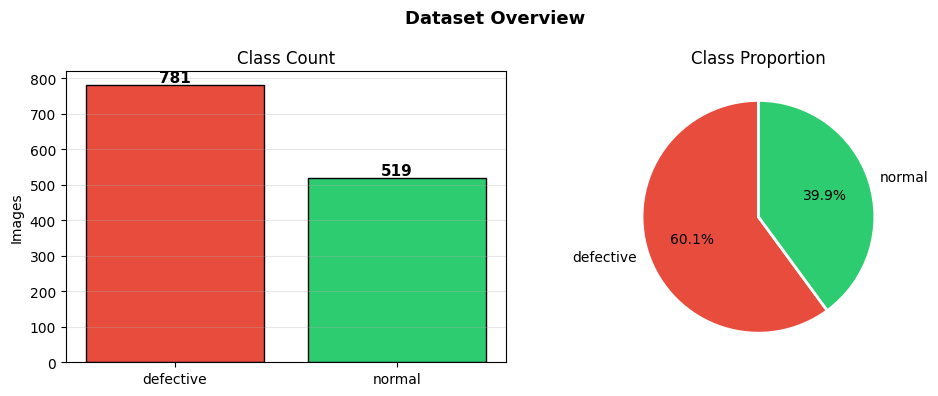

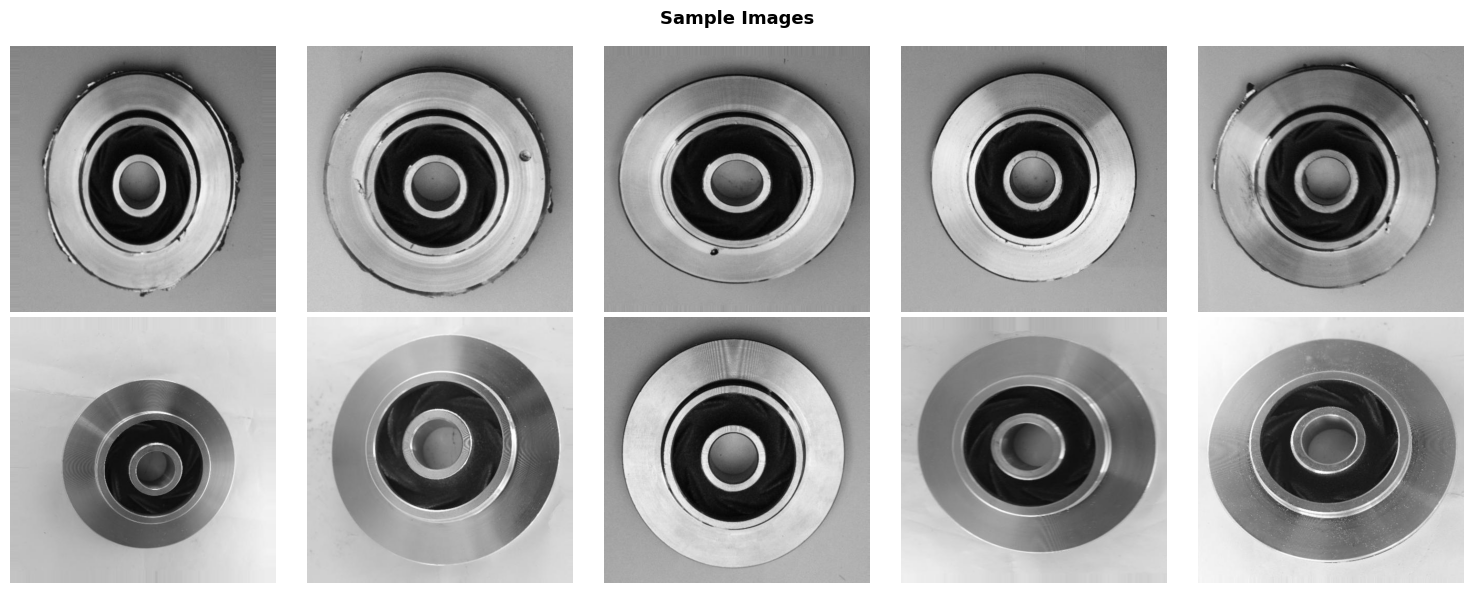

In [2]:
# Collect all image paths and string labels
images, labels = [], []
for label, folder in [("defective", "def_front"), ("normal", "ok_front")]:
    for path in sorted((DATA_DIR / folder).glob("*.*")):
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            images.append(str(path))
            labels.append(label)

counts = Counter(labels)
print(f"Total images : {len(images)}")
print(f"Defective    : {counts['defective']}")
print(f"Normal       : {counts['normal']}")
print(f"Imbalance    : {counts['defective']/counts['normal']:.2f}:1")

# ── Class distribution plots ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle("Dataset Overview", fontsize=13, fontweight="bold")
colors = ["#E74C3C", "#2ECC71"]

# Bar chart
ax = axes[0]
bars = ax.bar(counts.keys(), counts.values(), color=colors, edgecolor="black")
for bar, cnt in zip(bars, counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 8,
            f"{cnt}", ha="center", fontweight="bold", fontsize=11)
ax.set_title("Class Count"); ax.set_ylabel("Images"); ax.grid(axis="y", alpha=0.3)

# Pie chart
axes[1].pie(counts.values(), labels=counts.keys(), autopct="%1.1f%%",
            colors=colors, startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[1].set_title("Class Proportion")
plt.tight_layout(); plt.show()

# ── Sample images ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Sample Images", fontsize=13, fontweight="bold")
for row, (cls, color) in enumerate([("defective","#E74C3C"), ("normal","#2ECC71")]):
    samples = [p for p, l in zip(images, labels) if l == cls][:5]
    for col, path in enumerate(samples):
        axes[row][col].imshow(Image.open(path).convert("RGB"))
        axes[row][col].axis("off")
        if col == 0:
            axes[row][col].set_ylabel(cls.upper(), color=color,
                                       fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()

## 3 — Split, Dataset & DataLoaders
**Split:** 70% train | 15% val | 15% test — stratified so each split keeps the same class ratio.  
**Augmentation:** applied only on training data to avoid data leakage.

In [3]:
# ── Stratified Split ──────────────────────────────────────────────────────
X_train, X_temp, y_train, y_temp = train_test_split(
    images, labels, test_size=0.30, stratify=labels, random_state=SEED)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train : {len(X_train):,}  {dict(Counter(y_train))}")
print(f"Val   : {len(X_val):,}  {dict(Counter(y_val))}")
print(f"Test  : {len(X_test):,}  {dict(Counter(y_test))}")

# ── Dataset ───────────────────────────────────────────────────────────────
CLASS_TO_IDX = {"defective": 0, "normal": 1}
MEAN = [0.485, 0.456, 0.406]   # ImageNet mean
STD  = [0.229, 0.224, 0.225]   # ImageNet std

class CastingDataset(Dataset):
    def __init__(self, paths, labels, augment=False):
        self.paths  = paths
        self.labels = [CLASS_TO_IDX[l] for l in labels]

        if augment:
            # Training: random flips, crop, colour jitter
            self.transform = transforms.Compose([
                transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
                transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
                transforms.RandomHorizontalFlip(),
                transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
                transforms.ToTensor(),
                transforms.Normalize(MEAN, STD),
            ])
        else:
            # Val / Test: just resize and normalise — no randomness
            self.transform = transforms.Compose([
                transforms.Resize((IMG_SIZE, IMG_SIZE)),
                transforms.ToTensor(),
                transforms.Normalize(MEAN, STD),
            ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(img), self.labels[idx]

# ── DataLoaders ───────────────────────────────────────────────────────────
train_loader = DataLoader(CastingDataset(X_train, y_train, augment=True),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(CastingDataset(X_val,   y_val),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(CastingDataset(X_test,  y_test),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"\nTrain batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")
print(f"Test  batches : {len(test_loader)}")

Train : 910  {'defective': 547, 'normal': 363}
Val   : 195  {'defective': 117, 'normal': 78}
Test  : 195  {'defective': 117, 'normal': 78}

Train batches : 29
Val   batches : 7
Test  batches : 7


## 4 — Model & Training
**EfficientNet-B0** pretrained on ImageNet.  
We replace the last layer (1000 classes → 2 classes) and fine-tune the entire model at once with a low learning rate `1e-4` — this is simpler and avoids the complexity of two-phase training.  
**Weighted loss** handles any remaining class imbalance automatically.

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s]


Model    : EfficientNet-B0
Params   : 4,010,110

Class weights — defective: 0.832 | normal: 1.253

Epoch | Train Loss |  Val Loss |  Val F1
──────────────────────────────────────────
    1 |     0.4870 |    0.3888 |  0.8850  ✅ saved
    2 |     0.2367 |    0.1606 |  0.9746  ✅ saved
    3 |     0.0948 |    0.0747 |  0.9692
    4 |     0.0581 |    0.0281 |  0.9870  ✅ saved
    5 |     0.0351 |    0.0301 |  0.9870
    6 |     0.0230 |    0.0424 |  0.9782
    7 |     0.0295 |    0.0278 |  0.9870
    8 |     0.0129 |    0.0185 |  0.9914  ✅ saved
    9 |     0.0119 |    0.0258 |  0.9870
   10 |     0.0092 |    0.0206 |  0.9914
   11 |     0.0141 |    0.0352 |  0.9870
   12 |     0.0120 |    0.0265 |  0.9914
   13 |     0.0167 |    0.0186 |  0.9914

⛔ Early stopping at epoch 13 — best F1: 0.9914


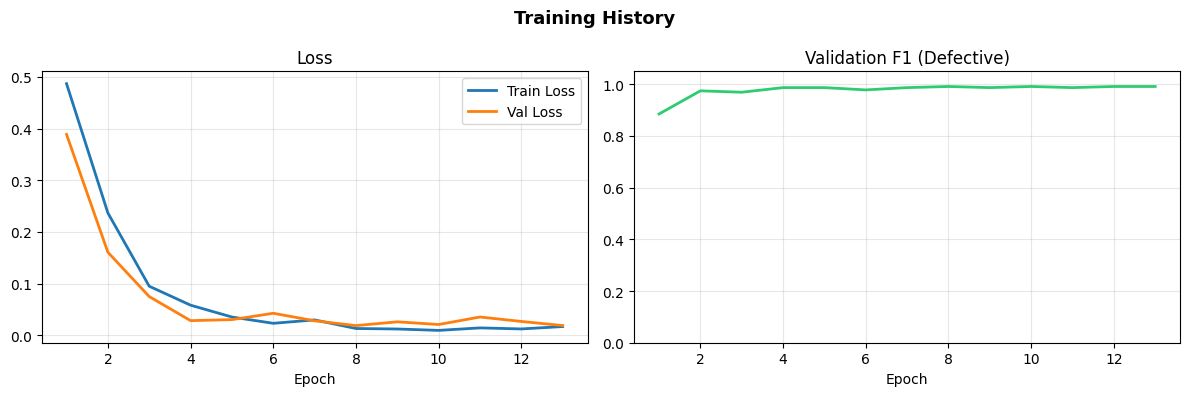

In [4]:
# ── Model ─────────────────────────────────────────────────────────────────
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"Model    : EfficientNet-B0")
print(f"Params   : {total_params:,}")

# ── Weighted loss (handles class imbalance) ───────────────────────────────
counts_train = Counter(y_train)
total_train  = len(y_train)
class_weights = torch.tensor([
    total_train / (2 * counts_train["defective"]),
    total_train / (2 * counts_train["normal"])
], dtype=torch.float).to(DEVICE)
print(f"\nClass weights — defective: {class_weights[0]:.3f} | normal: {class_weights[1]:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# ── Training & Validation Step ────────────────────────────────────────────
def run_epoch(loader, train=False):
    model.train(train)
    total_loss, all_preds, all_true = 0, [], []
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            if train:
                optimizer.zero_grad()
            out  = model(imgs)
            loss = criterion(out, lbls)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(lbls)
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_true.extend(lbls.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    f1 = f1_score(all_true, all_preds, pos_label=0, zero_division=0)
    return avg_loss, f1

# ── Training Loop ─────────────────────────────────────────────────────────
history = []
best_f1, patience_counter = 0, 0

print(f"\n{'Epoch':>5} | {'Train Loss':>10} | {'Val Loss':>9} | {'Val F1':>7}")
print("─" * 42)

for epoch in range(1, EPOCHS + 1):
    train_loss, _    = run_epoch(train_loader, train=True)
    val_loss, val_f1 = run_epoch(val_loader,   train=False)
    scheduler.step()

    history.append({"epoch": epoch, "train_loss": train_loss,
                    "val_loss": val_loss, "val_f1": val_f1})
    print(f"{epoch:>5} | {train_loss:>10.4f} | {val_loss:>9.4f} | {val_f1:>7.4f}", end="")

    if val_f1 > best_f1:
        best_f1 = val_f1
        patience_counter = 0
        torch.save(model.state_dict(), OUTPUT_DIR / "best_model.pt")
        print("  ✅ saved", end="")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n\n⛔ Early stopping at epoch {epoch} — best F1: {best_f1:.4f}")
            break
    print()

# ── Plot Training Curves ──────────────────────────────────────────────────
df_h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Training History", fontsize=13, fontweight="bold")

axes[0].plot(df_h["epoch"], df_h["train_loss"], label="Train Loss", linewidth=2)
axes[0].plot(df_h["epoch"], df_h["val_loss"],   label="Val Loss",   linewidth=2)
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(df_h["epoch"], df_h["val_f1"], color="#2ECC71", linewidth=2)
axes[1].set_title("Validation F1 (Defective)"); axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 1.05); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 5 — Final Evaluation on Test Set
Load the best saved model and evaluate on the held-out test set.  
Test set is used **only here** — it was never seen during training or threshold tuning.

  TEST SET RESULTS
              precision    recall  f1-score   support

   defective     1.0000    1.0000    1.0000       117
      normal     1.0000    1.0000    1.0000        78

    accuracy                         1.0000       195
   macro avg     1.0000    1.0000    1.0000       195
weighted avg     1.0000    1.0000    1.0000       195

ROC-AUC : 0.0000


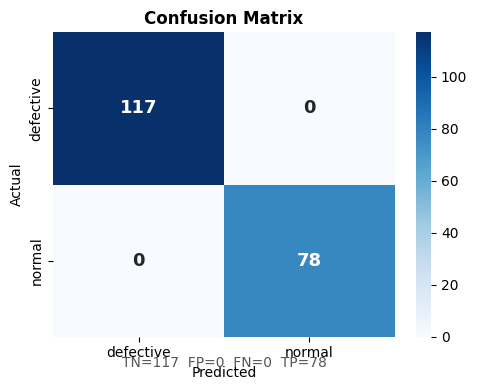


✅ Model saved → /kaggle/working/outputs/final_model.pt


In [5]:
# ── Load Best Model ───────────────────────────────────────────────────────
model.load_state_dict(torch.load(OUTPUT_DIR / "best_model.pt", map_location=DEVICE))
model.eval()

# ── Collect Predictions ───────────────────────────────────────────────────
all_preds, all_true, all_probs = [], [], []
with torch.no_grad():
    for imgs, lbls in test_loader:
        out   = model(imgs.to(DEVICE))
        probs = torch.softmax(out, dim=1)[:, 0]   # P(defective)
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_true.extend(lbls.numpy())
        all_probs.extend(probs.cpu().numpy())

# ── Metrics ───────────────────────────────────────────────────────────────
print("=" * 50)
print("  TEST SET RESULTS")
print("=" * 50)
print(classification_report(all_true, all_preds,
                             target_names=["defective", "normal"], digits=4))
print(f"ROC-AUC : {roc_auc_score(all_true, all_probs):.4f}")

# ── Confusion Matrix ──────────────────────────────────────────────────────
cm = confusion_matrix(all_true, all_preds)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["defective", "normal"],
            yticklabels=["defective", "normal"],
            annot_kws={"size": 13, "weight": "bold"})
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix", fontweight="bold")
tn, fp, fn, tp = cm.ravel()
ax.text(0.5, -0.1, f"TN={tn}  FP={fp}  FN={fn}  TP={tp}",
        ha="center", transform=ax.transAxes, fontsize=10, color="#555")
plt.tight_layout(); plt.show()

# ── Save Final Model with Metadata ───────────────────────────────────────
torch.save({
    "model_state":  model.state_dict(),
    "model_name":   "EfficientNet-B0",
    "class_to_idx": CLASS_TO_IDX,
    "img_size":     IMG_SIZE,
    "mean":         MEAN,
    "std":          STD,
}, OUTPUT_DIR / "final_model.pt")
print(f"\n✅ Model saved → {OUTPUT_DIR}/final_model.pt")

In [6]:
#error analysis code 
# ==========================================
# ERROR ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import os


model.eval()

wrong_images = []
wrong_labels = []
wrong_preds = []


with torch.no_grad():

    for imgs, labels in test_loader:

        imgs = imgs.to(DEVICE)

        outputs = model(imgs)

        preds = torch.argmax(outputs, dim=1)


        for i in range(len(labels)):

            if preds[i].cpu() != labels[i]:

                wrong_images.append(
                    imgs[i].cpu()
                )

                wrong_labels.append(
                    labels[i].item()
                )

                wrong_preds.append(
                    preds[i].item()
                )


print("Total Wrong Predictions:", len(wrong_images))


# Display mistakes

plt.figure(figsize=(15,10))


for i in range(min(12,len(wrong_images))):

    img = wrong_images[i]

    # undo normalization
    img = img.permute(1,2,0).numpy()

    plt.subplot(3,4,i+1)

    plt.imshow(img)

    plt.axis("off")

    plt.title(
        f"True: {wrong_labels[i]} | Pred: {wrong_preds[i]}"
    )


plt.show()

Total Wrong Predictions: 0


<Figure size 1500x1000 with 0 Axes>

In [10]:

from collections import Counter

print("===== DATASET DISTRIBUTION =====")

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"\n{name} samples: {len(X)}")
    print("Classes:", dict(Counter(y)))
    print("Percentage:", {
        k: round(v / len(y) * 100, 2)
        for k, v in Counter(y).items()
    })


===== DATASET DISTRIBUTION =====

Train samples: 910
Classes: {'defective': 547, 'normal': 363}
Percentage: {'defective': 60.11, 'normal': 39.89}

Validation samples: 195
Classes: {'defective': 117, 'normal': 78}
Percentage: {'defective': 60.0, 'normal': 40.0}

Test samples: 195
Classes: {'defective': 117, 'normal': 78}
Percentage: {'defective': 60.0, 'normal': 40.0}


In [11]:

import hashlib
from PIL import Image
from collections import defaultdict

def get_hash(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        content = str(img.size).encode() + img.tobytes()
        return hashlib.sha256(content).hexdigest()

def check_duplicates(A, B, name):
    hashes_A = defaultdict(list)

    for path in A:
        hashes_A[get_hash(path)].append(path)

    duplicates = []

    for path in B:
        h = get_hash(path)
        if h in hashes_A:
            duplicates.append((hashes_A[h][0], path))

    print(f"\n{name}: {len(duplicates)} duplicates")

    for pair in duplicates[:5]:
        print(pair)

    return duplicates

train_val = check_duplicates(
    X_train, X_val, "Train vs Validation"
)

train_test = check_duplicates(
    X_train, X_test, "Train vs Test"
)

val_test = check_duplicates(
    X_val, X_test, "Validation vs Test"
)

print("\n===== LEAKAGE SUMMARY =====")

if not (train_val or train_test or val_test):
    print("PASS: No exact image duplicates found.")
else:
    print("WARNING: Exact duplicates found!")



Train vs Validation: 0 duplicates

Train vs Test: 0 duplicates

Validation vs Test: 0 duplicates

===== LEAKAGE SUMMARY =====
PASS: No exact image duplicates found.


In [12]:

from sklearn.metrics import roc_auc_score
import numpy as np

# defective = 0 in original class mapping
y_defective = (np.array(all_true) == 0).astype(int)

# all_probs stores P(defective)
auc = roc_auc_score(y_defective, all_probs)

print(f"Corrected Defective ROC-AUC: {auc:.4f}")


Corrected Defective ROC-AUC: 1.0000
